# 9장 행동의 도입 (실습)

7장의 일반화 좌표 캡슐에 행동 u 를 더한다(버전 0.4). Hydar 는 이제 자기 속도를 정할 수 있다(x′ = u). 생성 모델에는 행동이 없고, 「나는 사전 깊이로 가고 있다」는 편향된 운동 방정식만 있다.

1. 첫 실험: 2 초 동안은 지각만, 그 뒤 행동을 켠다
2. 전방 모델: 정확, 부호, 차수별 부호
3. 임베딩 차수
4. 잡음의 매끄러움과 필요한 행동 학습률
5. 정밀도의 균형이 행동을 끌어내는가
6. 움직이는 사전, 동적 평형

마지막으로 행동 학습률이 너무 클 때 무엇이 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 10.0
t = np.arange(0, T + dt / 2, dt)
N = t.size
T_ACT = 2.0                                     # 이 시각부터 행동을 켠다
print(f"시간 점 {N} 개, 행동은 {T_ACT} 초부터")

시간 점 2001 개, 행동은 2.0 초부터


## 1. 생성 과정과 도구

운동 방정식은 x′ = a_gp x + b_gp u (a_gp = 0, b_gp = 1), 곧 Hydar 가 자기 속도를 정한다. 감각 사상은 앞 장들의 시그모이드다. 일반화 감각과 전방 모델 ∂ỹ/∂u 는 5.3 의 식에 a = 0 을 넣은 것이다.

- ỹ = [y, g′u, g″u², g‴u³]
- ∂ỹ/∂u = [0, g′, 2u g″, 3u² g‴]

In [2]:
def _e(x): return np.exp(5 - x / 5)
def g_gp(x):    return 25 - 16 / (1 + _e(x))
def dg_gp(x):   return -16 / 5 * _e(x) / (1 + _e(x))**2
def ddg_gp(x):  e = _e(x); return -16 / 25 * e * (e - 1) / (1 + e)**3
def dddg_gp(x): e = _e(x); return -16 / 125 * e * (e**2 - 4 * e + 1) / (1 + e)**4

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

def sensor_exact(y, p, x, u):
    full = [y, dg_gp(x) * u, ddg_gp(x) * u**2, dddg_gp(x) * u**3]
    return np.array(full[:p + 1]).reshape(-1, 1)

def fwd_model(p, x, u, method):
    """행동이 일반화 감각을 바꾸는 정도 ∂ỹ/∂u."""
    exact = np.array([0.0, dg_gp(x), 2 * u * ddg_gp(x), 3 * u**2 * dddg_gp(x)])[:p + 1]
    if method == "exact":
        return exact.reshape(-1, 1)
    if method == "sign":
        return -np.ones((p + 1, 1))                         # 「더 깊이 = 더 차갑게」 하나로 모든 차수를
    return np.sign(exact).reshape(-1, 1)                    # sign+: 차수마다 부호만

print("깊이 30, u = −2 에서 정확한 전방 모델:", np.round(fwd_model(3, 30.0, -2.0, "exact").ravel(), 4))

깊이 30, u = −2 에서 정확한 전방 모델: [ 0.     -0.6292 -0.2326  0.0543]


## 2. 캡슐 버전 0.4

지각은 7장과 같다. 생성 모델의 운동 방정식은 f = −μ + μv 로, 「나는 사전 깊이로 다가간다」는 편향이다. 행동은 행동 시각 이후에만 u̇ = −αu (∂ỹ/∂u)ᵀ Π̃z ε̃y 로 움직인다.

In [3]:
class ai_capsule:
    """일반화 좌표의 지각과 행동을 함께 하는 뉴런 묶음 (버전 0.4)."""

    def __init__(self, dt, mu_v0, p, s_w, s_z, a_mu, a_u, s2_w, s2_z, fwd_method="exact"):
        self.dt, self.p, self.a_mu, self.a_u, self.fwd_method = dt, p, a_mu, a_u, fwd_method
        self.mu = np.zeros((p + 1, 1)); self.mu[0] = mu_v0      # 믿음은 사전에서, 멈춘 채 출발
        self.u = 0.0
        self.D, self.I = derivativeD(p), np.eye(p + 1)
        self.A = -1.0 * self.I                                  # 생성 모델: f = −μ + μv
        self.Pi_w = inv(np.kron(temporalC(p, s2_w), s_w))
        self.Pi_z = inv(np.kron(temporalC(p, s2_z), s_z))
        self.e0 = self.I[:, :1]

    def ai_step(self, mu_v, y, act):
        mu = self.mu
        mv = self.e0 * mu_v
        g1 = dg_gp(mu[0, 0])
        eps_x = (self.D - self.A) @ mu - mv                      # 예측 오차 (운동)
        eps_y = y - (self.e0 * g_gp(mu[0, 0]) + (1 - self.e0) * g1 * mu)   # 예측 오차 (감각)
        F = 0.5 * (eps_x.T @ self.Pi_w @ eps_x + eps_y.T @ self.Pi_z @ eps_y).item()
        dF = (self.D - self.A).T @ self.Pi_w @ eps_x - g1 * self.Pi_z @ eps_y
        self.mu = mu + self.dt * (self.D @ mu - self.a_mu * dF)              # 지각
        if act:
            fwd = fwd_model(self.p, mu[0, 0], self.u, self.fwd_method)
            self.u += self.dt * -self.a_u * (fwd.T @ self.Pi_z @ eps_y).item()   # 행동
        return self.u, F, self.mu[0, 0]


S2 = {"none": 1 / 64, "smooth": 1 / 2000, "white": 1e-5}     # 잡음 종류별로 생성 모델이 가정하는 매끄러움

def simulation(mu_v, x_init, s_w=0.1, s_z=0.1, noise="none", a_mu=1.0, a_u=50.0, p=1,
               fwd="exact", t_act=T_ACT, seed=42):
    mu_v = np.broadcast_to(mu_v, (N,)).astype(float)
    s2 = S2[noise]
    rng = np.random.default_rng(seed); np.random.seed(seed)
    w = makeNoise(s_w, s2, t)[0] if noise == "smooth" else None
    z = makeNoise(s_z, s2, t)[0] if noise == "smooth" else None
    cap = ai_capsule(dt, mu_v[0], p, s_w, s_z, a_mu, a_u, s2, s2, fwd)
    out = {k: np.zeros(N) for k in ["x", "y", "mu", "u", "F"]}
    out["x"][0], out["mu"][0], out["y"][0] = x_init, mu_v[0], g_gp(x_init)
    u = 0.0
    with np.errstate(all="ignore"):
        for i in range(1, N):
            xd = u
            if noise == "smooth":
                xd += w[i]
            elif noise == "white":
                xd += rng.standard_normal() * np.sqrt(s_w)
            x = out["x"][i - 1] + dt * xd
            y = g_gp(x) + (z[i] if noise == "smooth" else rng.standard_normal() * np.sqrt(s_z) if noise == "white" else 0.0)
            yt = sensor_exact(y, p, x, u)
            u, F, m = cap.ai_step(mu_v[i], yt, t[i] > t_act)
            out["x"][i], out["y"][i], out["mu"][i], out["u"][i], out["F"][i] = x, y, m, u, F
    out["mu_v"] = mu_v
    return out


def arrival(r, target=25.0, tol=0.5):
    """행동 시각 이후 |x − 목표| < tol 안에 계속 머물기 시작한 시각."""
    bad = np.where(np.abs(r["x"] - target) >= tol)[0]
    return t[bad[-1] + 1] if bad.size and bad[-1] + 1 < N else (np.inf if bad.size else 0.0)

def plot_run(runs, t_act=T_ACT):
    fig, ax = plt.subplots(4, 1, sharex=True, figsize=(6.4, 6.0))
    colors = ["#E32C24", "#1f77b4", "#2ca02c"]
    for (label, r), c in zip(runs.items(), colors):
        ax[0].plot(t, r["x"], color=c, lw=1.5, label=f"실제 깊이 ({label})")
        ax[0].plot(t, r["mu"], color=c, lw=0.9, ls="--", label=f"믿음 μ ({label})")
        ax[1].plot(t, r["y"], color=c, lw=1.2)
        ax[2].plot(t, r["u"], color=c, lw=1.2)
        ax[3].plot(t[1:], r["F"][1:], color=c, lw=1.2)
    r0 = next(iter(runs.values()))
    ax[0].plot(t, r0["mu_v"], color="#575753", lw=0.8, label="사전 μv")
    ax[1].plot(t, g_gp(r0["mu_v"]), color="#575753", lw=0.8)
    for a in ax:
        a.axvline(t_act, color="#999999", ls=":", lw=0.8)
    ax[0].set_ylabel("깊이"); ax[1].set_ylabel("수온 y"); ax[2].set_ylabel("행동 u"); ax[3].set_ylabel("자유 에너지")
    ax[3].set_xlabel("시간 (초)")
    ax[0].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    fig.tight_layout()
    plt.show()

print("ai_capsule v0.4, simulation 준비 완료")

ai_capsule v0.4, simulation 준비 완료


## 3. 실험 1 — 지각한 다음 행동한다

Hydar 는 깊이 30 에서 춥다. 생성 모델은 25(17 °C)로 가고 있다고 믿는다. 처음 2 초는 행동을 막고 지각만 한다. 두 분산 0.1, 잡음 없음(s² = 1/64), p = 1, αu = 50.

In [4]:
r1 = simulation(25.0, 30.0)
for sec in [1.99, 2.5, 3, 4, 6, 10]:
    k = int(round(sec / dt))
    print(f"t={sec:5.2f}s  깊이 {r1['x'][k]:6.3f}  믿음 {r1['mu'][k]:6.3f}  수온 {r1['y'][k]:6.3f}  행동 {r1['u'][k]:+7.3f}  F {r1['F'][k]:8.3f}")
print(f"깊이 25±0.5 에 머물기 시작한 시각: {arrival(r1):.2f}s")

t= 1.99s  깊이 30.000  믿음 28.826  수온 13.303  행동  +0.000  F    6.258
t= 2.50s  깊이 28.602  믿음 28.366  수온 14.237  행동  -3.564  F    1.961
t= 3.00s  깊이 27.024  믿음 27.254  수온 15.403  행동  -2.630  F    1.207
t= 4.00s  깊이 25.404  믿음 25.585  수온 16.677  행동  -0.791  F    0.221
t= 6.00s  깊이 24.984  믿음 24.991  수온 17.013  행동  +0.004  F    0.000
t=10.00s  깊이 25.000  믿음 25.000  수온 17.000  행동  +0.000  F    0.000
깊이 25±0.5 에 머물기 시작한 시각: 3.89s


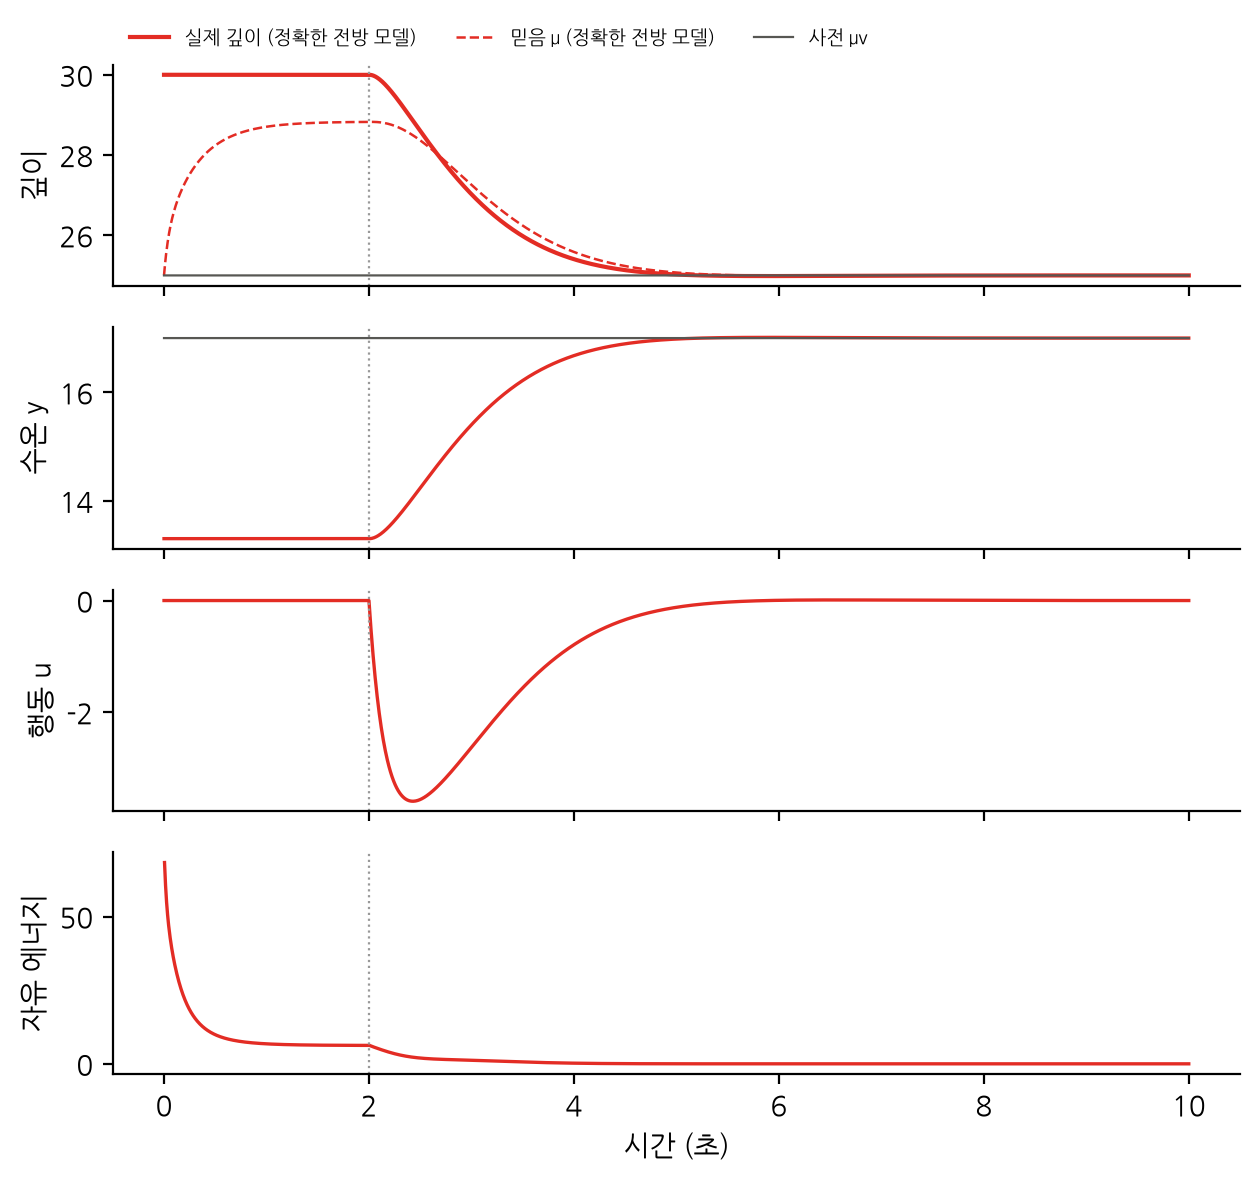

In [5]:
plot_run({"정확한 전방 모델": r1})

## 4. 실험 2 — 예상한 대로일 때

사전과 실제가 모두 25 다.

In [6]:
r2 = simulation(25.0, 25.0)
print(f"최대 |u| = {np.abs(r2['u']).max():.2e},  최대 F = {r2['F'].max():.2e},  마지막 깊이 {r2['x'][-1]:.4f}")

최대 |u| = 0.00e+00,  최대 F = 0.00e+00,  마지막 깊이 25.0000


## 5. 전방 모델 비교

정확한 전방 모델(αu = 50), 모든 차수에 −1 을 쓰는 부호 모델(αu = 1), 차수마다 정확한 부호만 쓰는 sign+ 모델(αu = 50)을 비교한다.

In [7]:
print("전방 모델        αu    도착 시각   최대 u    10초 깊이")
for name, fwd, a_u in [("exact", "exact", 50), ("sign", "sign", 1), ("sign", "sign", 50), ("sign+", "sign+", 50)]:
    r = simulation(25.0, 30.0, fwd=fwd, a_u=a_u)
    print(f"{name:12s}  {a_u:4d}    {arrival(r):6.2f}s   {np.abs(r['u']).max():6.3f}   {r['x'][-1]:7.3f}")

전방 모델        αu    도착 시각   최대 u    10초 깊이
exact           50      3.89s    3.595    25.000
sign             1      3.77s    3.756    25.001


sign            50      4.79s   16.771    25.011
sign+           50      3.90s    3.702    25.000


## 6. 임베딩 차수

p = 1, 2, 3 에 αu = 200 을 쓴다. 원본처럼 감각 예측 오차 제곱합도 함께 본다.

In [8]:
print(" p    도착 시각   최대 u    Σ(y − g(μ))²")
for p in [1, 2, 3]:
    r = simulation(25.0, 30.0, p=p, a_u=200)
    print(f" {p}    {arrival(r):6.2f}s   {np.abs(r['u']).max():6.3f}   {np.sum((g_gp(r['mu']) - r['y'])**2):9.2f}")

 p    도착 시각   최대 u    Σ(y − g(μ))²
 1      3.98s    3.894      658.44
 2      4.46s    4.180      446.10


 3      4.44s    3.962      523.94


## 7. 잡음의 매끄러움과 행동 학습률

정확한 전방 모델은 첫 칸이 0 이므로 행동은 감각 속도 오차 이상에만 반응한다. 그 칸의 무게는 일반화 정밀도의 (1, 1) 원소 Π̃z[1,1] 이고, 매끄러움 s² 가 작을수록 작아진다. 같은 행동을 얻으려면 αu 를 그만큼 키워야 한다.

In [9]:
print("잡음      s²        Π̃z[1,1]     αu·Π̃z[1,1] 를 맞춘 αu   도착 시각   10초 깊이")
base = inv(np.kron(temporalC(1, S2["none"]), 0.1))[1, 1] * 50
for noise in ["none", "smooth", "white"]:
    pz = inv(np.kron(temporalC(1, S2[noise]), 0.1))[1, 1]
    a_u = base / pz
    r = simulation(25.0, 30.0, noise=noise, a_u=a_u)
    print(f"{noise:7s}  {S2[noise]:8.2g}   {pz:9.4g}        {a_u:10.0f}            {arrival(r):6.2f}s    {r['x'][-1]:7.3f}")

잡음      s²        Π̃z[1,1]     αu·Π̃z[1,1] 를 맞춘 αu   도착 시각   10초 깊이
none        0.016      0.3125                50              3.89s     25.000


smooth     0.0005        0.01              1562              3.68s     24.955


white       1e-05      0.0002             78125              3.68s     24.987


## 8. 정밀도의 균형이 행동을 끌어내는가

기준(σw² = σz² = 0.1)과 사전을 덜 믿는 경우(σw² = 10), 감각을 덜 믿는 경우(σz² = 10)를 비교한다. 행동 시각 직전의 믿음과 10 초 뒤의 깊이를 본다.

In [10]:
print("경우              2초 믿음   10초 깊이   최대 u")
for name, s_w, s_z in [("기준 (0.1, 0.1)", 0.1, 0.1), ("사전 약함 (10, 0.1)", 10, 0.1), ("감각 약함 (0.1, 10)", 0.1, 10)]:
    r = simulation(25.0, 30.0, s_w=s_w, s_z=s_z)
    print(f"{name:16s}   {r['mu'][int(T_ACT / dt)]:7.3f}    {r['x'][-1]:7.3f}   {np.abs(r['u']).max():6.3f}")

경우              2초 믿음   10초 깊이   최대 u
기준 (0.1, 0.1)       28.826     25.000    3.595


사전 약함 (10, 0.1)     29.745     21.644    1.392
감각 약함 (0.1, 10)     25.169     29.485    0.119


## 9. 움직이는 사전과 동적 평형

사전을 μv(t) = 25 + 15 sin(3t) 로 움직인다. 원본처럼 사전을 강하게 믿고(σw² = 0.03) 감각은 약하게(σz² = 10), 전방 모델은 부호 모델, αμ = 5, αu = 1800 이고 행동은 처음부터 켠다. 이어서 사전과 실제가 모두 25 인데 유색 잡음이 있는 경우를 본다.

In [11]:
r_sin = simulation(25 + 15 * np.sin(3 * t), 25.0, s_w=0.03, s_z=10, a_mu=5, a_u=1800, fwd="sign", t_act=0.0)
lag = np.argmax([np.corrcoef(r_sin["x"][200 + k:], r_sin["mu_v"][200:N - k])[0, 1] for k in range(200)])
amp = (r_sin["x"][t > 4].max() - r_sin["x"][t > 4].min()) / 2
print(f"움직이는 사전: 진폭 15 를 {amp:.2f} 로 따라가고, 위상은 {lag * dt:.3f}s 늦다 (사전 주기 {2 * np.pi / 3:.2f}s)")

r_eq = simulation(25.0, 25.0, noise="smooth", a_u=50)
print(f"동적 평형: 깊이 표준편차 {r_eq['x'][t > 2].std():.3f}, 행동 표준편차 {r_eq['u'][t > 2].std():.3f}, 행동이 0 이 아닌 비율 {np.mean(np.abs(r_eq['u'][t > 2]) > 1e-3):.2f}")

움직이는 사전: 진폭 15 를 14.40 로 따라가고, 위상은 0.160s 늦다 (사전 주기 2.09s)


동적 평형: 깊이 표준편차 0.127, 행동 표준편차 0.071, 행동이 0 이 아닌 비율 0.98


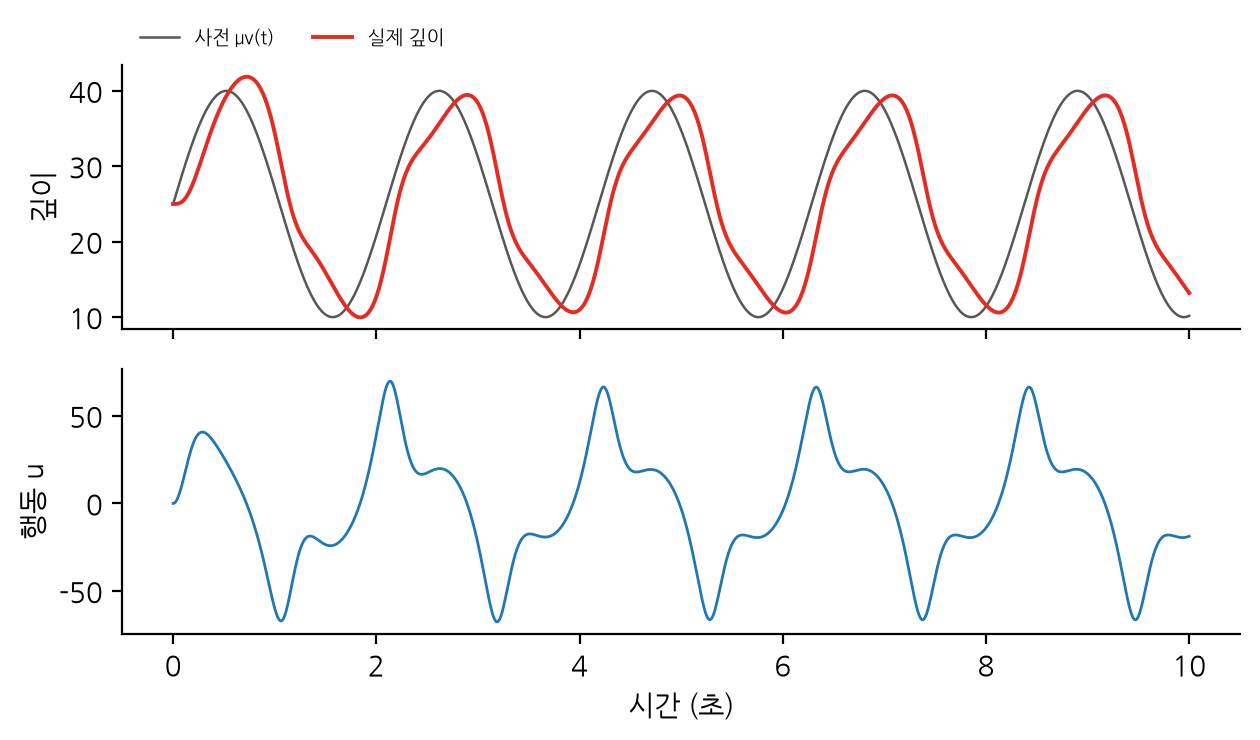

In [12]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 3.8))
ax[0].plot(t, r_sin["mu_v"], color="#575753", lw=0.9, label="사전 μv(t)")
ax[0].plot(t, r_sin["x"], color="#E32C24", lw=1.4, label="실제 깊이")
ax[0].set_ylabel("깊이"); ax[0].legend(frameon=False, fontsize=7, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax[1].plot(t, r_sin["u"], color="#1f77b4", lw=1.0)
ax[1].set_ylabel("행동 u"); ax[1].set_xlabel("시간 (초)")
fig.tight_layout(); plt.show()

## 10. 실패 조건 — 행동 학습률이 너무 크다

유색 잡음(s² = 1/2000)에서 αu 를 50 부터 120000 까지 올린다.

In [13]:
print("αu        도착 시각    최대 |u|      도착 뒤 |u| 의 최대")
for a_u in [50, 1500, 15000, 60000, 120000]:
    r = simulation(25.0, 30.0, noise="smooth", a_u=a_u)
    arr = arrival(r)
    after = np.abs(r["u"][t > (arr if np.isfinite(arr) else T) + 0.5]).max() if np.isfinite(arr) and arr + 0.5 < T else np.nan
    print(f"{a_u:7d}   {arr:8.2f}s   {np.abs(r['u']).max():10.4g}   {after:10.4g}")

αu        도착 시각    최대 |u|      도착 뒤 |u| 의 최대


     50        infs        1.768          nan


   1500       3.68s        3.876       0.5078


  15000       3.75s        4.395       0.5177


  60000       3.76s        5.572       0.5255


 120000        infs         2440          nan


## 결론

- 생성 모델에 행동이 없어도, 편향된 운동 방정식과 행동의 경사 하강만으로 Hydar 는 바라는 깊이로 간다.
- 지각만 하던 동안 줄어든 자유 에너지가 행동을 켜면 더 줄어든다.
- 전방 모델은 부호만 맞으면 되고, 크기는 행동 학습률이 맡는다.
- 잡음이 거칠수록 감각 속도의 정밀도가 작아지므로 행동 학습률을 그 비율만큼 키워야 한다.
- 행동을 끌어내려면 사전이 감각보다 정밀해 믿음이 사전 쪽에 있어야 하고, 감각 정밀도는 행동의 배율이 된다.
- 잡음 속에서는 목표 근처에서 끊임없이 조금씩 움직인다 — 동적 평형.
- 행동 학습률이 지나치면 행동이 목표 근처에서 튄다.